In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from abc import ABC, abstractmethod
# Apresenta a Dinamica do MDP de forma gráfica
import graphviz

In [ ]:
class GridWorldDynamicBuilder:
    """
    Construtor genérico de dinâmica P[s][a] para GridWorlds.

    ─── CONVENÇÃO (Padrão A — cartesiano) ───────────────────────
        (x, y) com y crescendo PARA CIMA.
        (0, 0) = canto INFERIOR esquerdo.
        y = 0 é a LINHA DE BAIXO; y = nlin-1 é a LINHA DE CIMA.

    ─── ESTADO s ────────────────────────────────────────────────
        s = row * ncol + x, com row = 0 sendo a LINHA DO TOPO.
        Ou seja:
            s = 0           -> (x=0, y=nlin-1)  -> canto SUP. ESQ.
            s = nlin*ncol-1 -> (x=ncol-1, y=0)  -> canto INF. DIR.
        Isso mantém compatibilidade com o P_dyn do MDP original.

    ─── AÇÕES (Padrão A) ────────────────────────────────────────
        0: Cima    -> dy = +1
        1: Direita -> dx = +1
        2: Baixo   -> dy = -1
        3: Esquerda-> dx = -1
    """
    ACOES = {
        0: (0, +1),   # Cima    (aumenta y)
        1: (1, 0),    # Direita
        2: (0, -1),   # Baixo   (diminui y)
        3: (-1, 0),   # Esquerda
    }

    def __init__(self, nlin: int = 5, ncol: int = 5,
                 rec_padrao: float = 0.0, rec_parede: float = -1.0):
        self.nlin = nlin
        self.ncol = ncol
        self.n_states = nlin * ncol
        self.n_actions = len(self.ACOES)

        self.saltos = {}
        self.recompensas_padrao = {}
        self.terminais = set()
        self.obstaculos = set()
        self.recompensa_passo_padrao = rec_padrao
        self.recompensa_parede = rec_parede

    # ---------- Conversões (Padrão A) ----------
    def pos_to_state(self, x: int, y: int) -> int:
        """
        (x, y) com y crescendo PARA CIMA -> índice s.
        row = (nlin-1) - y  (porque row=0 é o TOPO, y=nlin-1 é o TOPO).
        """
        row = (self.nlin - 1) - y
        return row * self.ncol + x

    def state_to_pos(self, s: int) -> tuple:
        """
        índice s -> (x, y) com y crescendo PARA CIMA.
        """
        row = s // self.ncol
        col = s % self.ncol
        y = (self.nlin - 1) - row
        return col, y

    # ---------- Saltos / teleportes ----------
    def adicionar_salto(self, s_orig: int, s_dest: int, reward: float):
        self.saltos[s_orig] = (s_dest, reward)

    def adicionar_salto_pos(self, orig_x, orig_y, dest_x, dest_y, reward):
        self.adicionar_salto(
            self.pos_to_state(orig_x, orig_y),
            self.pos_to_state(dest_x, dest_y),
            reward,
        )

    # ---------- Terminais / obstáculos ----------
    def adicionar_terminal(self, s: int):
        self.terminais.add(s)

    def adicionar_obstaculo(self, s: int):
        self.obstaculos.add(s)

    # ---------- Build ----------
    def build_P(self) -> dict:
        P = {s: {a: [] for a in range(self.n_actions)}
             for s in range(self.n_states)}

        for s in range(self.n_states):
            x, y = self.state_to_pos(s)

            # 1) Terminal
            if s in self.terminais:
                for a in range(self.n_actions):
                    P[s][a] = [(1.0, s, 0.0, True)]
                continue

            # 2) Salto incondicional
            if s in self.saltos:
                next_s, reward = self.saltos[s]
                for a in range(self.n_actions):
                    P[s][a] = [(1.0, next_s, reward, False)]
                continue

            # 3) Movimento padrão
            for a, (dx, dy) in self.ACOES.items():
                nx, ny = x + dx, y + dy

                if nx < 0 or nx >= self.ncol or ny < 0 or ny >= self.nlin:
                    next_s = s
                    reward = self.recompensa_parede
                elif self.pos_to_state(nx, ny) in self.obstaculos:
                    next_s = s
                    reward = self.recompensa_parede
                else:
                    next_s = self.pos_to_state(nx, ny)
                    reward = self.recompensas_padrao.get(
                        next_s, self.recompensa_passo_padrao)

                done = next_s in self.terminais
                P[s][a] = [(1.0, next_s, reward, done)]

        return P

In [ ]:
class Tabuleiro(gym.Env):
    """
    Gym.Env do tabuleiro MDP.

    ─── CONVENÇÃO (Padrão A) ────────────────────────────────────
        _state_to_coords(s) -> (x, y) com y crescendo PARA CIMA.
        y = 0 é a LINHA DE BAIXO; y = nlin-1 é a LINHA DE CIMA.
        s = 0 -> (0, nlin-1) -> canto SUPERIOR esquerdo.
    """

    def __init__(self, P_Din_MDP=None, nlin=4, ncol=4,
                 estado_inicial=0, max_steps=500):
        if not (nlin > 0 and ncol > 0):
            raise AssertionError('nlin e ncol devem ser positivas')
        if estado_inicial < 0 or estado_inicial >= nlin * ncol:
            raise AssertionError(
                f'estado_inicial deve estar entre 0 e {nlin*ncol-1}')
        if P_Din_MDP is None:
            raise AssertionError('A Dinâmica do MDP deve ser definida')

        nestados = nlin * ncol
        if nestados != max(P_Din_MDP.keys()) + 1 or \
           nestados != len(P_Din_MDP):
            raise AssertionError(
                f'A Dinâmica do MDP deve ter {nlin*ncol} estados')

        super().__init__()
        self.nlin, self.ncol = nlin, ncol
        self.num_acoes = 4
        self.passo = 0
        self.max_steps = max_steps
        self.P_Din_MDP = P_Din_MDP

        self.action_space = spaces.Discrete(self.num_acoes)
        self.dict_acoes = {0: 'cima', 1: 'dir', 2: 'baixo', 3: 'esq'}
        self.dict_acoes_inv = {'cima': 0, 'dir': 1, 'baixo': 2, 'esq': 3}

        self.num_estados = nestados
        self.estado_inicial = estado_inicial
        self.state = self.estado_inicial
        self.state_pos = self._state_to_coords(self.state)
        self.state_space = spaces.Discrete(self.num_estados)

        self.dict_estados = {i: f's{i}' for i in range(self.num_estados)}
        self.dict_estados_inv = {f's{i}': i for i in range(self.num_estados)}

        self.visited_states = {self.estado_inicial}

        self.render()

    # ---------- Conversões (Padrão A) ----------
    def _state_to_coords(self, state):
        """s -> (x, y) com y crescendo PARA CIMA."""
        row = state // self.ncol
        col = state % self.ncol
        y = (self.nlin - 1) - row
        return col, y

    def _coords_to_state(self, x, y):
        """(x, y) com y crescendo PARA CIMA -> s."""
        row = (self.nlin - 1) - y
        return row * self.ncol + x

    # ---------- Gym API ----------
    def step(self, acao):
        transitions = self.P_Din_MDP[self.state][acao]
        probs = [p for p, _, _, _ in transitions]
        outcomes = [(s2, r, d) for _, s2, r, d in transitions]

        idx = np.random.choice(len(outcomes), p=probs)
        next_state, reward, terminated = outcomes[idx]

        self.state = next_state
        self.state_pos = self._state_to_coords(self.state)
        self.visited_states.add(self.state)
        self.passo += 1

        truncated = self.passo >= self.max_steps
        self.render()
        return self.state, reward, terminated, truncated, {}

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.state = self.estado_inicial
        self.state_pos = self._state_to_coords(self.state)
        self.visited_states = {self.estado_inicial}
        self.render()
        return self.state, {}

    def _is_terminal(self, s):
        if s not in self.P_Din_MDP:
            return True
        for a in self.P_Din_MDP[s]:
            for _, _, _, done in self.P_Din_MDP[s][a]:
                if not done:
                    return False
        return True

    # ---------- Render (Padrão A — SEM invert_yaxis) ----------
    def render(self):
        fig, ax = plt.subplots(figsize=(self.ncol, self.nlin))
        ax.set_aspect('equal')

        for x in range(self.ncol + 1):
            ax.axvline(x, color='black', lw=1)
        for y in range(self.nlin + 1):
            ax.axhline(y, color='black', lw=1)

        ax.set_xlim(0, self.ncol)
        ax.set_ylim(0, self.nlin)
        ax.set_xticks([]); ax.set_yticks([])

        for s in range(self.num_estados):
            x, y = self._state_to_coords(s)
            xc, yc = x + 0.5, y + 0.5

            ax.text(xc, yc, self.dict_estados[s],
                    ha='center', va='center', fontsize=12)

            if s == self.estado_inicial:
                ax.text(x + 0.1, y + 0.9, 'I', ha='left', va='top',
                        fontsize=10, color='green', fontweight='bold')
            if self._is_terminal(s):
                ax.text(x + 0.1, y + 0.9, 'T', ha='left', va='top',
                        fontsize=10, color='red', fontweight='bold')
            if s in self.visited_states and s != self.state:
                ax.text(xc, yc + 0.2, 'x', ha='center', va='center',
                        fontsize=16, color='gray')
            if s == self.state:
                ax.text(xc, yc - 0.2, 'o', ha='center', va='center',
                        fontsize=16, color='blue', fontweight='bold')

        plt.title('Tabuleiro MDP (Padrão A)')
        plt.show()

    def close(self):
        plt.close()

In [ ]:
import random

def sortear_posicoes_wumpus(nlin=10, ncol=10):
    """
    Sorteia as posições do Wumpus, do ouro e dos buracos em um grid.

    Parâmetros:
        nlin (int): número de linhas do grid (padrão 10)
        ncol (int): número de colunas do grid (padrão 10)

    Retorna:
        posicao_wumpus (tuple): posição (x, y) do Wumpus
        posicao_ouro (tuple): posição (x, y) do ouro
        lista_posicao_buracos (list): lista de tuplas (x, y) com posições dos buracos
    """

    # Posição inicial do agente: canto superior esquerdo
    posicao_agente = (0, nlin - 1)

    # Gera todas as posições possíveis do grid, exceto a posição inicial do agente
    todas_posicoes = [
        (x, y)
        for x in range(ncol)
        for y in range(nlin)
        if (x, y) != posicao_agente
    ]

    # Calcula a quantidade de buracos: 15% do total de células
    qtd_buracos = int(0.15 * nlin * ncol)

    # Sorteia as posições sem reposição
    posicoes_sorteadas = random.sample(todas_posicoes, qtd_buracos + 2)

    # Distribui as posições sorteadas
    posicao_wumpus = posicoes_sorteadas[0]
    posicao_ouro = posicoes_sorteadas[1]
    lista_posicao_buracos = posicoes_sorteadas[2:]

    return posicao_wumpus, posicao_ouro, lista_posicao_buracos




In [ ]:
for i in range(3):
  wumpus, ouro, buracos = sortear_posicoes_wumpus(10, 10)
  print(f"--- Execução {i + 1} ---")
  print(f"Wumpus: {wumpus}")
  print(f"Ouro:   {ouro}")
  print(f"Buracos ({len(buracos)}): {buracos}")
  print()

--- Execução 1 ---
Wumpus: (2, 3)
Ouro:   (6, 9)
Buracos (15): [(3, 6), (0, 5), (4, 6), (6, 5), (5, 1), (1, 0), (1, 6), (4, 9), (8, 6), (9, 1), (8, 8), (7, 7), (4, 7), (0, 7), (3, 4)]

--- Execução 2 ---
Wumpus: (2, 4)
Ouro:   (3, 1)
Buracos (15): [(8, 3), (1, 6), (5, 8), (1, 2), (8, 0), (9, 8), (6, 9), (6, 6), (4, 2), (6, 0), (4, 8), (5, 6), (3, 4), (3, 6), (4, 9)]

--- Execução 3 ---
Wumpus: (6, 7)
Ouro:   (2, 1)
Buracos (15): [(0, 2), (1, 2), (5, 0), (1, 6), (6, 6), (6, 3), (6, 1), (0, 3), (4, 8), (0, 8), (6, 0), (0, 5), (3, 2), (4, 7), (3, 5)]



In [ ]:
def obter_vizinhos(nlin=10, ncol=10, posicao_wumpus=None, posicao_ouro=None, lista_posicao_buracos=None):
    """
    Calcula as células que percebem luz (vizinhas ao ouro), vento (vizinhas
    aos buracos) e cheiro (vizinhas ao Wumpus). Considera apenas as 4
    direções ortogonais e respeita os limites do grid.

    Percepções podem se sobrepor: uma mesma célula pode estar em mais de
    uma lista (ex.: luz + vento, ou vento + cheiro).

    Retorna:
        lista_posicao_luz (list): células vizinhas ao ouro
        lista_posicao_vento (list): células vizinhas a algum buraco (sem duplicatas)
        lista_posicao_cheiro (list): células vizinhas ao Wumpus
        percepcoes (dict): mapeia cada célula -> set de percepções presentes
    """

    if lista_posicao_buracos is None:
        lista_posicao_buracos = []

    direcoes = [(0, 1), (0, -1), (1, 0), (-1, 0)]

    def vizinhos_validos(posicao):
        if posicao is None:
            return []
        x, y = posicao
        return [
            (x + dx, y + dy)
            for dx, dy in direcoes
            if 0 <= x + dx < ncol and 0 <= y + dy < nlin
        ]

    # Luz: vizinhos do ouro
    lista_posicao_luz = vizinhos_validos(posicao_ouro)

    # Cheiro: vizinhos do Wumpus
    lista_posicao_cheiro = vizinhos_validos(posicao_wumpus)

    # Vento: união dos vizinhos de todos os buracos (set evita duplicatas
    # dentro da própria lista de vento)
    conjunto_vento = set()
    for buraco in lista_posicao_buracos:
        conjunto_vento.update(vizinhos_validos(buraco))
    lista_posicao_vento = list(conjunto_vento)

    # ---- Agregação das percepções por célula (permite sobreposição) ----
    percepcoes = {}
    for celula in lista_posicao_luz:
        percepcoes.setdefault(celula, set()).add("luz")
    for celula in lista_posicao_vento:
        percepcoes.setdefault(celula, set()).add("vento")
    for celula in lista_posicao_cheiro:
        percepcoes.setdefault(celula, set()).add("cheiro")

    return lista_posicao_luz, lista_posicao_vento, lista_posicao_cheiro, percepcoes




In [ ]:
# Exemplo de uso

import random
random.seed(7)

nlin, ncol = 10, 10
wumpus, ouro, buracos = sortear_posicoes_wumpus(nlin, ncol)
luz, vento, cheiro, percepcoes = obter_vizinhos(nlin, ncol, wumpus, ouro, buracos)

print(f"Wumpus: {wumpus}")
print(f"Ouro:   {ouro}")
print(f"Buracos ({len(buracos)}): {buracos}\n")

print(f"Luz   ({len(luz)}):    {sorted(luz)}")
print(f"Vento ({len(vento)}): {sorted(vento)}")
print(f"Cheiro({len(cheiro)}): {sorted(cheiro)}\n")

# Células com mais de uma percepção (sobreposição)
sobrepostas = {c: p for c, p in percepcoes.items() if len(p) > 1}
print(f"Células com percepções sobrepostas ({len(sobrepostas)}):")
for celula, percs in sorted(sobrepostas.items()):
  print(f"  {celula}: {sorted(percs)}")

Wumpus: (4, 2)
Ouro:   (2, 0)
Buracos (15): [(5, 1), (8, 4), (0, 6), (1, 0), (6, 9), (1, 3), (4, 7), (7, 5), (0, 7), (6, 5), (2, 8), (0, 4), (1, 2), (5, 6), (5, 4)]

Luz   (3):    [(1, 0), (2, 1), (3, 0)]
Vento (43): [(0, 0), (0, 2), (0, 3), (0, 5), (0, 6), (0, 7), (0, 8), (1, 1), (1, 2), (1, 3), (1, 4), (1, 6), (1, 7), (1, 8), (2, 0), (2, 2), (2, 3), (2, 7), (2, 9), (3, 7), (3, 8), (4, 1), (4, 4), (4, 6), (4, 8), (5, 0), (5, 2), (5, 3), (5, 5), (5, 7), (5, 9), (6, 1), (6, 4), (6, 5), (6, 6), (6, 8), (7, 4), (7, 5), (7, 6), (7, 9), (8, 3), (8, 5), (9, 4)]
Cheiro(4): [(3, 2), (4, 1), (4, 3), (5, 2)]

Células com percepções sobrepostas (2):
  (4, 1): ['cheiro', 'vento']
  (5, 2): ['cheiro', 'vento']


In [ ]:
# ============================================================
# Interfaces e avaliadores (idênticos ao MDP original —
# operam apenas em `s`, não dependem de convenção de x/y)
# ============================================================
class AvaliadorMDP(ABC):
    def __init__(self, env, xp, gamma=0.99):
        self.env, self.xp, self.gamma = env, xp, gamma

    @abstractmethod
    def q_valor(self, s, a, V): ...

    @abstractmethod
    def q_valores(self, V): ...


class AvaliadorIterativo(AvaliadorMDP):
    def q_valor(self, s, a, V):
        total = 0.0
        for p, s2, r, _ in self.env.P_Din_MDP[s][a]:
            total += p * (r + self.gamma * V[s2])
        return total

    def q_valores(self, V):
        return self.xp.array([
            [self.q_valor(s, a, V) for a in range(self.env.num_acoes)]
            for s in range(self.env.num_estados)
        ])


class AvaliadorVetorizado(AvaliadorMDP):
    def __init__(self, env, xp, gamma):
        super().__init__(env, xp, gamma)
        self.T, self.R, self.mask_term = self._construir(env, xp)

    @staticmethod
    def _construir(env, xp):
        S, A = env.num_estados, env.num_acoes
        T = xp.zeros((S, A, S), dtype=xp.float32)
        R = xp.zeros((S, A), dtype=xp.float32)
        mask = xp.zeros(S, dtype=xp.bool_)
        for s in range(S):
            mask[s] = env._is_terminal(s)
            for a in range(A):
                for p, s2, r, _ in env.P_Din_MDP.get(s, {}).get(a, []):
                    T[s, a, s2] += p
                    R[s, a]    += p * r
        return T, R, mask

    def q_valor(self, s, a, V):
        return float(self.R[s, a] + self.gamma * self.T[s, a] @ V)

    def q_valores(self, V):
        return self.R + self.gamma * self.xp.einsum('san,n->sa', self.T, V)


class AvaliadorVetorizadoJax(AvaliadorMDP):
    """Versão JAX (não usada por padrão — requer instalação do JAX)."""
    def __init__(self, env, xp, gamma):
        super().__init__(env, xp, gamma)
        self.T, self.R, self.mask_term = self._construir(env, xp)

    @staticmethod
    def _construir(env, xp):
        S, A = env.num_estados, env.num_acoes
        T = xp.zeros((S, A, S), dtype=xp.float32)
        R = xp.zeros((S, A), dtype=xp.float32)
        mask = xp.zeros(S, dtype=xp.bool_)
        for s in range(S):
            mask = mask.at[s].set(env._is_terminal(s))
            for a in range(A):
                for p, s2, r, _ in env.P_Din_MDP.get(s, {}).get(a, []):
                    T = T.at[s, a, s2].add(p)
                    R = R.at[s, a].add(p * r)
        return T, R, mask

    def q_valor(self, s, a, V):
        return float(self.R[s, a] + self.gamma * self.T[s, a] @ V)

    def q_valores(self, V):
        return self.R + self.gamma * self.xp.einsum('san,n->sa', self.T, V)

In [ ]:
# ============================================================
# Template Method + algoritmos (idênticos ao MDP original)
# ============================================================
class AlgoritmoPlanejamento(ABC):
    def __init__(self, env, avaliador: AvaliadorMDP,
                 gamma=0.99, epsilon=1e-6):
        self.env, self.avaliador = env, avaliador
        self.gamma, self.epsilon = gamma, epsilon
        self.xp = avaliador.xp
        S = env.num_estados
        self.V = self.xp.zeros(S, dtype=self.xp.float32)
        self._politica_det = self.xp.zeros(S, dtype=self.xp.int32)
        self.politica = None

    def treinar(self, max_iteracoes=1000, reset=True):
        if reset:
            self.reset()
        for i in range(max_iteracoes):
            if self._passo(i) < self.epsilon:
                print(f"[{type(self).__name__} | "
                      f"{type(self.avaliador).__name__}] "
                      f"convergiu em {i+1} iterações.")
                break
        self._extrair_politica()
        return self.V, self.politica

    def reset(self):
        self.V = self.xp.zeros(self.env.num_estados, dtype=self.xp.float32)
        self._politica_det = self.xp.zeros(self.env.num_estados,
                                           dtype=self.xp.int32)
        self.politica = None

    @abstractmethod
    def _passo(self, i: int) -> float: ...

    @abstractmethod
    def _extrair_politica(self): ...


class IteracaoValor(AlgoritmoPlanejamento):
    def _passo(self, i):
        V_old = self.xp.copy(self.V)
        Q = self.avaliador.q_valores(V_old)
        self.V = self.xp.max(Q, axis=1)

        if hasattr(self.avaliador, 'mask_term'):
            self.V[self.avaliador.mask_term] = 0.0
        else:
            terminal_mask = self.xp.array(
                [self.env._is_terminal(s)
                 for s in range(self.env.num_estados)],
                dtype=self.xp.bool_)
            self.V[terminal_mask] = 0.0

        return float(self.xp.max(self.xp.abs(self.V - V_old)))

    def _extrair_politica(self):
        Q = self.avaliador.q_valores(self.V)
        self._politica_det = self.xp.argmax(Q, axis=1)

        stochastic_policy = []
        for s in range(self.env.num_estados):
            max_q = self.xp.max(Q[s])
            optimal_actions = self.xp.where(Q[s] == max_q)[0]
            stochastic_policy.append(optimal_actions.tolist())
        self.politica = stochastic_policy


class _BaseIteracaoPolitica(AlgoritmoPlanejamento, ABC):
    def _passo(self, i):
        V_old = self.xp.copy(self.V)
        self._avaliar()
        Q = self.avaliador.q_valores(self.V)
        nova_politica_det = self.xp.argmax(Q, axis=1)

        politica_estavel = bool(self.xp.all(
            nova_politica_det == self._politica_det))
        valor_estabilizado = float(
            self.xp.max(self.xp.abs(self.V - V_old))) < self.epsilon

        self._politica_det = nova_politica_det

        if i > 0 and politica_estavel and valor_estabilizado:
            return 0.0
        return 1.0

    def _extrair_politica(self):
        Q = self.avaliador.q_valores(self.V)
        stochastic_policy = []
        for s in range(self.env.num_estados):
            max_q = self.xp.max(Q[s])
            optimal_actions = self.xp.where(Q[s] == max_q)[0]
            stochastic_policy.append(optimal_actions.tolist())
        self.politica = stochastic_policy

    @abstractmethod
    def _avaliar(self): ...


class IteracaoPolitica(_BaseIteracaoPolitica):
    def _avaliar(self):
        while True:
            V_old = self.xp.copy(self.V)
            Q = self.avaliador.q_valores(V_old)
            idx = self.xp.arange(self.env.num_estados)
            self.V = Q[idx, self._politica_det]
            if float(self.xp.max(self.xp.abs(self.V - V_old))) < self.epsilon:
                break


class IteracaoPoliticaModificada(_BaseIteracaoPolitica):
    def __init__(self, env, avaliador, gamma=0.99, epsilon=1e-6, k=1):
        super().__init__(env, avaliador, gamma, epsilon)
        if k < 1:
            raise ValueError("k deve ser >= 1")
        self.k = k

    def _avaliar(self):
        idx = self.xp.arange(self.env.num_estados)
        for _ in range(self.k):
            Q = self.avaliador.q_valores(self.V)
            self.V = Q[idx, self._politica_det]

In [ ]:
class VisualizadorResultado:
    """
    Visualizador de V e pi no Padrão A:
        s -> (x, y) com y crescendo PARA CIMA.
        s0 em (0, nlin-1) aparece no canto SUPERIOR esquerdo.
    """
    ACOES_DXY = {
        0: ( 0,   0.3),   # Cima  -> +y
        1: ( 0.3, 0),     # Dir   -> +x
        2: ( 0,  -0.3),   # Baixo -> -y
        3: (-0.3, 0),     # Esq   -> -x
    }

    def __init__(self, tab, cmap_valores="viridis"):
        self.tab = tab
        self.cmap = plt.get_cmap(cmap_valores)

    def _para_numpy(self, x, dtype=None):
        if x is None:
            return None
        if hasattr(x, "get") and not isinstance(x, np.ndarray):
            x = x.get()
        elif hasattr(x, "cpu") and not isinstance(x, np.ndarray):
            x = x.cpu().numpy()
        return np.asarray(x, dtype=dtype)

    def _transicao_mais_provavel(self, s, a):
        return max(self.tab.P_Din_MDP[s][a], key=lambda t: t[0])[1]

    def _simular_politica(self, politica, s0=None, max_passos=500):
        tab = self.tab
        if s0 is None:
            s0 = tab.estado_inicial
        s = s0
        caminho = [s]
        for _ in range(max_passos):
            a = politica[s][0] if isinstance(politica[s], list) \
                else politica[s]
            a = int(a)
            s_prox = self._transicao_mais_provavel(s, a)
            if tab._is_terminal(s) or s_prox == s:
                break
            caminho.append(s_prox)
            if tab._is_terminal(s_prox):
                break
            s = s_prox
        return caminho

    def desenhar(self, V, politica, ax=None,
                 mostrar_valores=True, mostrar_setas=True,
                 mostrar_rastro=True, mostrar_estados=True, titulo=None):

        tab = self.tab
        V = self._para_numpy(V, dtype=float)

        if ax is None:
            fig, ax = plt.subplots(figsize=(tab.ncol, tab.nlin))

        vmin, vmax = float(V.min()), float(V.max())
        vnorm = np.zeros_like(V) if vmax - vmin < 1e-12 \
            else (V - vmin) / (vmax - vmin)

        caminho = set(self._simular_politica(politica)) \
            if mostrar_rastro else set()

        for s in range(tab.num_estados):
            x, y = tab._state_to_coords(s)
            terminal = tab._is_terminal(s)
            face = "#dddddd" if terminal else self.cmap(vnorm[s])

            ax.add_patch(Rectangle((x, y), 1, 1, facecolor=face,
                                   edgecolor="gray", linewidth=0.8, alpha=0.9))
            if s == tab.estado_inicial:
                ax.add_patch(Rectangle((x, y), 1, 1, facecolor="none",
                                       edgecolor="orange", linewidth=3))
            if terminal:
                ax.add_patch(Rectangle((x, y), 1, 1, facecolor="none",
                                       edgecolor="green", linewidth=2))

            if mostrar_estados:
                ax.text(x + 0.08, y + 0.92, tab.dict_estados[s],
                        ha="left", va="top", fontsize=7,
                        color="black", alpha=0.6)
            if mostrar_valores:
                ax.text(x + 0.5, y + 0.5, f"{V[s]:.2f}",
                        ha="center", va="center", fontsize=9,
                        color="white", fontweight="bold")

        if mostrar_setas:
            for s in range(tab.num_estados):
                if tab._is_terminal(s):
                    continue
                x, y = tab._state_to_coords(s)
                actions = politica[s] if isinstance(politica[s], list) \
                    else [politica[s]]
                for action in actions:
                    dx, dy = self.ACOES_DXY[int(action)]
                    cor = "red" if s in caminho else "blue"
                    lw = 2.2 if s in caminho else 1.2
                    ax.annotate("",
                                xy=(x + 0.5 + dx, y + 0.5 + dy),
                                xytext=(x + 0.5, y + 0.5),
                                arrowprops=dict(arrowstyle="->",
                                                color=cor, lw=lw,
                                                mutation_scale=10))

        ax.set_xlim(0, tab.ncol); ax.set_ylim(0, tab.nlin)
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])

        if titulo:
            ax.set_title(titulo, fontsize=12, fontweight="bold")
        return ax

    def comparar(self, resultados, salvar=None, figsize_por_painel=4.0):
        n = len(resultados)
        fig, axes = plt.subplots(1, n,
                                 figsize=(figsize_por_painel*n,
                                          figsize_por_painel),
                                 squeeze=False)
        for ax, (nome, (V, pi)) in zip(axes[0], resultados.items()):
            self.desenhar(V, pi, ax=ax, titulo=nome)
        plt.tight_layout()
        if salvar:
            plt.savefig(salvar, dpi=150, bbox_inches="tight")
        return fig

In [ ]:
# ============================================================
# WumpusMDP — fachada que compõe GridWorldDynamicBuilder + Tabuleiro
# ============================================================
#
# MODOS:
#   "classico"  — agente começa em (0, nlin-1), objetivo é o ouro.
#   "reverso"   — agente começa onde está o ouro, objetivo é (0, nlin-1).
#
# CONVENÇÃO (Padrão A):
#   - Estado s = row * ncol + x, com row = 0 na LINHA DO TOPO.
#   - Ações: 0=Cima(+y), 1=Direita(+x), 2=Baixo(-y), 3=Esquerda(-x).
#
# CONTRATOS DAS FUNÇÕES EXTERNAS:
#   sortear_posicoes_wumpus(nlin, ncol) -> (wumpus, ouro, buracos)
#   obter_vizinhos(nlin, ncol, wumpus, ouro, buracos)
#       -> (luz, vento, cheiro, percepcoes)
# ============================================================

from typing import Dict, List, Tuple, Optional
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


class WumpusMDP:
    """
    Fábrica do ambiente Wumpus World no Padrão A, com modos clássico e reverso.

    Composição:
        - GridWorldDynamicBuilder: monta P[s][a]
        - Tabuleiro (gym.Env):     expõe a interface Gymnasium
        - Este WumpusMDP:          orquestra, valida e expõe utilidades
    """

    # -----------------------------
    # Recompensas padrão
    # -----------------------------
    REC_PADRAO = -1.0
    REC_PAREDE = -2.0
    REC_OURO   = 1000.0
    REC_WUMPUS = -1000.0
    REC_BURACO = -1000.0
    REC_CHEIRO = -3.0
    REC_VENTO  = -3.0
    REC_LUZ    = 1.0

    MODOS_VALIDOS = ("classico", "reverso")

    def __init__(
        self,
        nlin: int = 10,
        ncol: int = 10,
        seed: Optional[int] = None,
        gamma: float = 0.99,
        max_steps: int = 500,
        modo: str = "classico",                            # NOVO
        rec_padrao: float = REC_PADRAO,
        rec_parede: float = REC_PAREDE,
        rec_ouro:   float = REC_OURO,
        rec_wumpus: float = REC_WUMPUS,
        rec_buraco: float = REC_BURACO,
        rec_cheiro: float = REC_CHEIRO,
        rec_vento:  float = REC_VENTO,
        rec_luz:    float = REC_LUZ,
    ):
        # --- Validações ---
        if nlin <= 0 or ncol <= 0:
            raise AssertionError("nlin e ncol devem ser positivos")
        if not (0.0 < gamma < 1.0):
            raise AssertionError("gamma deve estar em (0, 1)")
        if modo not in self.MODOS_VALIDOS:                  # NOVO
            raise ValueError(
                f"modo deve ser um de {self.MODOS_VALIDOS}, recebido '{modo}'"
            )

        self.nlin, self.ncol = nlin, ncol
        self.seed, self.gamma, self.max_steps = seed, gamma, max_steps
        self.modo = modo                                    # NOVO

        # --- Guarda recompensas ---
        self.rec_padrao, self.rec_parede = rec_padrao, rec_parede
        self.rec_ouro,   self.rec_wumpus = rec_ouro,   rec_wumpus
        self.rec_buraco, self.rec_cheiro = rec_buraco, rec_cheiro
        self.rec_vento,  self.rec_luz    = rec_vento,  rec_luz

        # --- 1) Sorteia posições ---
        if seed is not None:
            random.seed(seed)

        (self.posicao_wumpus,
         self.posicao_ouro,
         self.lista_buracos) = sortear_posicoes_wumpus(nlin, ncol)

        # --- 2) Percepções ---
        (self.lista_luz,
         self.lista_vento,
         self.lista_cheiro,
         self.percepcoes) = obter_vizinhos(
            nlin, ncol,
            self.posicao_wumpus,
            self.posicao_ouro,
            self.lista_buracos,
        )

        # --- 3) Builder interno ---
        self._builder = GridWorldDynamicBuilder(
            nlin=self.nlin, ncol=self.ncol,
            rec_padrao=self.rec_padrao,
            rec_parede=self.rec_parede,
        )

        # --- 4) Define s0 e s_terminal_positivo conforme o modo  # NOVO
        self.s_base = self._builder.pos_to_state(0, nlin - 1)   # sempre = 0
        self.s_ouro = self._builder.pos_to_state(*self.posicao_ouro)

        if modo == "classico":
            self.s0 = self.s_base
            self.s_terminal_positivo = self.s_ouro
        else:  # "reverso"
            self.s0 = self.s_ouro
            self.s_terminal_positivo = self.s_base

        # --- 5) Dinâmica P[s][a] (depende dos papéis definidos acima) ---
        self.P_dyn = self._construir_P_dyn(self._builder)

        # --- 6) Sanidade ---
        self._validar_configuracao()

        # --- 7) Cache do Tabuleiro ---
        self._tabuleiro = None

    # ============================================================
    # Conversões (Padrão A)
    # ============================================================
    def pos_to_state(self, x: int, y: int) -> int:
        if not (0 <= x < self.ncol and 0 <= y < self.nlin):
            raise ValueError(f"({x},{y}) fora do grid {self.ncol}x{self.nlin}")
        return self._builder.pos_to_state(x, y)

    def state_to_pos(self, s: int) -> Tuple[int, int]:
        if not (0 <= s < self.nlin * self.ncol):
            raise ValueError(f"estado {s} inválido")
        return self._builder.state_to_pos(s)

    # ============================================================
    # Construção do P_dyn
    # ============================================================
    def _construir_P_dyn(self, builder: GridWorldDynamicBuilder) -> Dict:
        # Percepções: sobreposição SOMADA
        def acumular(celula, valor):
            s = builder.pos_to_state(*celula)
            builder.recompensas_padrao[s] = (
                builder.recompensas_padrao.get(s, 0.0) + valor
            )

        for celula in self.lista_luz:    acumular(celula, self.rec_luz)
        for celula in self.lista_vento:  acumular(celula, self.rec_vento)
        for celula in self.lista_cheiro: acumular(celula, self.rec_cheiro)

        # Terminal positivo: depende do modo
        # A recompensa é atribuída ao estado de destino, então:
        #   - no clássico: recompensas_padrao[s_ouro] = rec_ouro
        #   - no reverso:  recompensas_padrao[s_base] = rec_ouro
        builder.recompensas_padrao[self.s_terminal_positivo] = self.rec_ouro
        builder.adicionar_terminal(self.s_terminal_positivo)

        # Wumpus e buracos são terminais negativos em ambos os modos
        s_wumpus = builder.pos_to_state(*self.posicao_wumpus)
        builder.recompensas_padrao[s_wumpus] = self.rec_wumpus
        builder.adicionar_terminal(s_wumpus)

        for b in self.lista_buracos:
            s_b = builder.pos_to_state(*b)
            builder.recompensas_padrao[s_b] = self.rec_buraco
            builder.adicionar_terminal(s_b)

        return builder.build_P()

    def _validar_configuracao(self):
        """Valida invariantes do modo escolhido."""
        # 1) O estado inicial nunca pode ser um terminal negativo
        assert self.s0 != self._builder.pos_to_state(*self.posicao_wumpus), \
            "Estado inicial caiu no Wumpus!"
        assert all(
            self.s0 != self._builder.pos_to_state(*b)
            for b in self.lista_buracos
        ), "Estado inicial caiu em um buraco!"

        # 2) O estado inicial não pode ser o terminal positivo
        assert self.s0 != self.s_terminal_positivo, \
            "Estado inicial coincide com o objetivo!"

        # 3) No clássico, o agente começa na base;
        #    no reverso, começa no ouro.
        if self.modo == "classico":
            assert self.s0 == self.s_base
        else:
            assert self.s0 == self.s_ouro

    # ============================================================
    # Fábrica do Tabuleiro
    # ============================================================
    def criar_tabuleiro(self, **kwargs):
        params = dict(
            P_Din_MDP=self.P_dyn,
            nlin=self.nlin,
            ncol=self.ncol,
            estado_inicial=self.s0,
            max_steps=self.max_steps,
        )
        params.update(kwargs)
        self._tabuleiro = Tabuleiro(**params)
        return self._tabuleiro

    # ============================================================
    # Renderização
    # ============================================================
    def render(self, ax=None, mostrar_estados=True,
               mostrar_percepcoes=True, titulo=None):
        if ax is None:
            fig, ax = plt.subplots(figsize=(self.ncol, self.nlin))

        ax.set_xlim(0, self.ncol)
        ax.set_ylim(0, self.nlin)
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])

        for x in range(self.ncol + 1):
            ax.axvline(x, color="black", lw=0.5, alpha=0.4)
        for y in range(self.nlin + 1):
            ax.axhline(y, color="black", lw=0.5, alpha=0.4)

        cor_ouro   = "#fff2a8"
        cor_wumpus = "#ffb3b3"
        cor_buraco = "#444444"
        cor_luz    = "#fffbe0"
        cor_vento  = "#d6e8ff"
        cor_cheiro = "#e8d6ff"

        if mostrar_percepcoes:
            for (cx, cy) in self.lista_luz:
                ax.add_patch(Rectangle((cx, cy), 1, 1,
                                       facecolor=cor_luz, alpha=0.6))
            for (cx, cy) in self.lista_vento:
                ax.add_patch(Rectangle((cx, cy), 1, 1,
                                       facecolor=cor_vento, alpha=0.6))
            for (cx, cy) in self.lista_cheiro:
                ax.add_patch(Rectangle((cx, cy), 1, 1,
                                       facecolor=cor_cheiro, alpha=0.6))

        # Ouro
        ox, oy = self.posicao_ouro
        ax.add_patch(Rectangle((ox, oy), 1, 1, facecolor=cor_ouro))
        ax.text(ox+0.5, oy+0.5, "O", ha="center", va="center",
                fontsize=14, fontweight="bold")

        # Wumpus
        wx, wy = self.posicao_wumpus
        ax.add_patch(Rectangle((wx, wy), 1, 1, facecolor=cor_wumpus))
        ax.text(wx+0.5, wy+0.5, "W", ha="center", va="center",
                fontsize=14, fontweight="bold", color="darkred")

        # Buracos
        for (bx, by) in self.lista_buracos:
            ax.add_patch(Rectangle((bx, by), 1, 1, facecolor=cor_buraco))
            ax.text(bx+0.5, by+0.5, "B", ha="center", va="center",
                    fontsize=12, fontweight="bold", color="white")

        # Base (canto superior esquerdo em Padrão A)
        bx, by = self.state_to_pos(self.s_base)
        ax.add_patch(Rectangle((bx, by), 1, 1, facecolor="none",
                               edgecolor="orange", linewidth=2, linestyle="--"))

        # Objetivo (destaca o terminal positivo)
        tx, ty = self.state_to_pos(self.s_terminal_positivo)
        ax.add_patch(Rectangle((tx, ty), 1, 1, facecolor="none",
                               edgecolor="red", linewidth=3))

        # Agente em s0
        a0x, a0y = self.state_to_pos(self.s0)
        ax.add_patch(Rectangle((a0x, a0y), 1, 1, facecolor="none",
                               edgecolor="green", linewidth=3))
        ax.text(a0x+0.5, a0y+0.5, "A", ha="center", va="center",
                fontsize=14, fontweight="bold", color="green")

        if mostrar_estados:
            for s in range(self.nlin * self.ncol):
                sx, sy = self.state_to_pos(s)
                if (sx, sy) in (self.posicao_ouro, self.posicao_wumpus):
                    continue
                if (sx, sy) in self.lista_buracos:
                    continue
                ax.text(sx+0.08, sy+0.92, f"s{s}",
                        ha="left", va="top", fontsize=7,
                        color="black", alpha=0.5)

        if titulo is None:
            titulo = f"Wumpus World — modo '{self.modo}'"
        ax.set_title(titulo, fontsize=12, fontweight="bold")
        return ax

    # ============================================================
    # Conveniências
    # ============================================================
    @property
    def posicoes(self) -> Dict[str, object]:
        return {
            "wumpus": self.posicao_wumpus,
            "ouro":   self.posicao_ouro,
            "buracos": self.lista_buracos,
        }

    @property
    def n_states(self) -> int:
        return self.nlin * self.ncol

    @property
    def n_actions(self) -> int:
        return 4

    # ============================================================
    # Representação
    # ============================================================
    def __repr__(self):
        a0x, a0y = self.state_to_pos(self.s0)
        tx, ty = self.state_to_pos(self.s_terminal_positivo)
        return (
            f"WumpusMDP({self.nlin}x{self.ncol}, seed={self.seed}, "
            f"gamma={self.gamma}, modo='{self.modo}')\n"
            f"  s0 = {self.s0}  ->  (x={a0x}, y={a0y})  [agente]\n"
            f"  objetivo = {self.s_terminal_positivo}  ->  (x={tx}, y={ty})\n"
            f"  Wumpus: {self.posicao_wumpus}\n"
            f"  Ouro:   {self.posicao_ouro}\n"
            f"  Buracos({len(self.lista_buracos)}): {self.lista_buracos}"
        )

In [ ]:
w_classico = WumpusMDP(nlin=10, ncol=10, seed=42, modo="classico")
print(w_classico)

WumpusMDP(10x10, seed=42, gamma=0.99, modo='classico')
  s0 = 0  ->  (x=0, y=9)  [agente]
  objetivo = 41  ->  (x=1, y=5)
  Wumpus: (8, 2)
  Ouro:   (1, 5)
  Buracos(15): [(0, 3), (9, 5), (3, 6), (3, 2), (2, 9), (1, 8), (1, 4), (8, 7), (7, 0), (1, 2), (7, 6), (5, 5), (0, 4), (2, 8), (3, 0)]


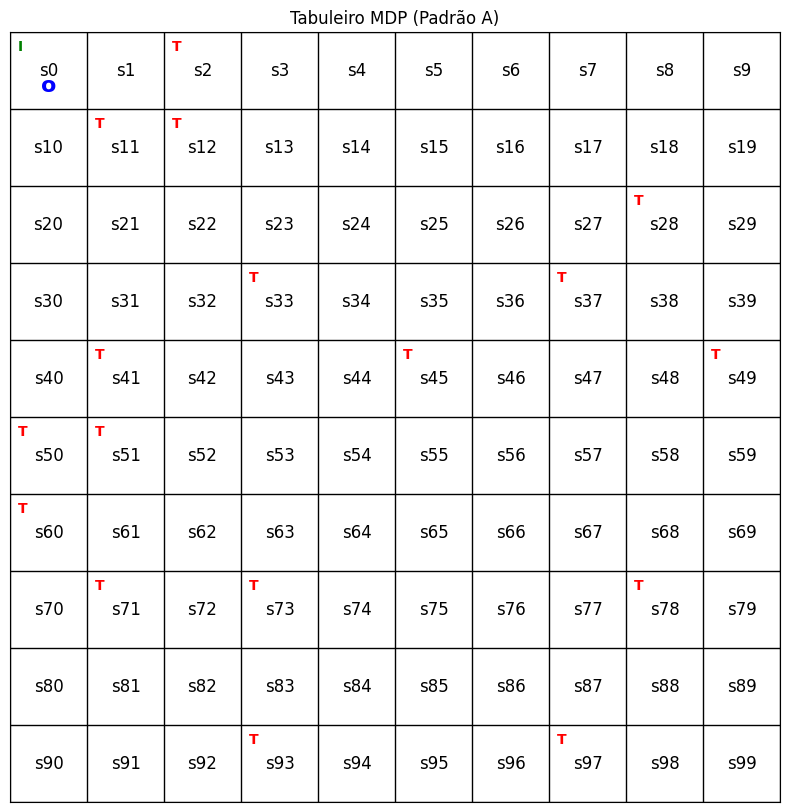

In [ ]:
env = w_classico.criar_tabuleiro()

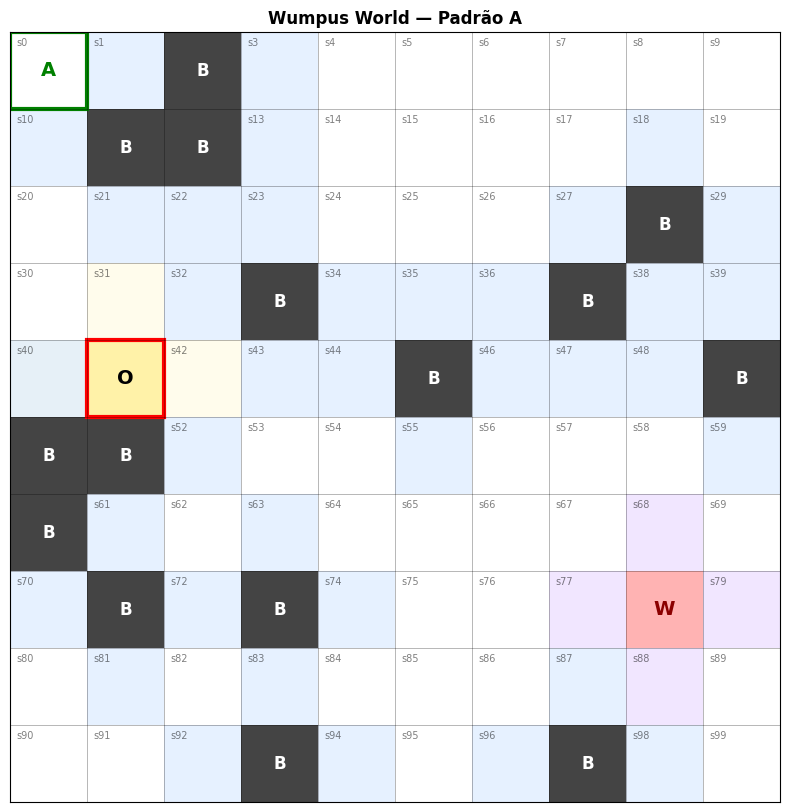

In [ ]:
w_classico.render(titulo="Wumpus World — Padrão A")
plt.show()

In [ ]:
aval = AvaliadorVetorizado(env, xp=np, gamma=w_classico.gamma)
vi = IteracaoValor(env, aval)
V, pi = vi.treinar()

[IteracaoValor | AvaliadorVetorizado] convergiu em 14 iterações.


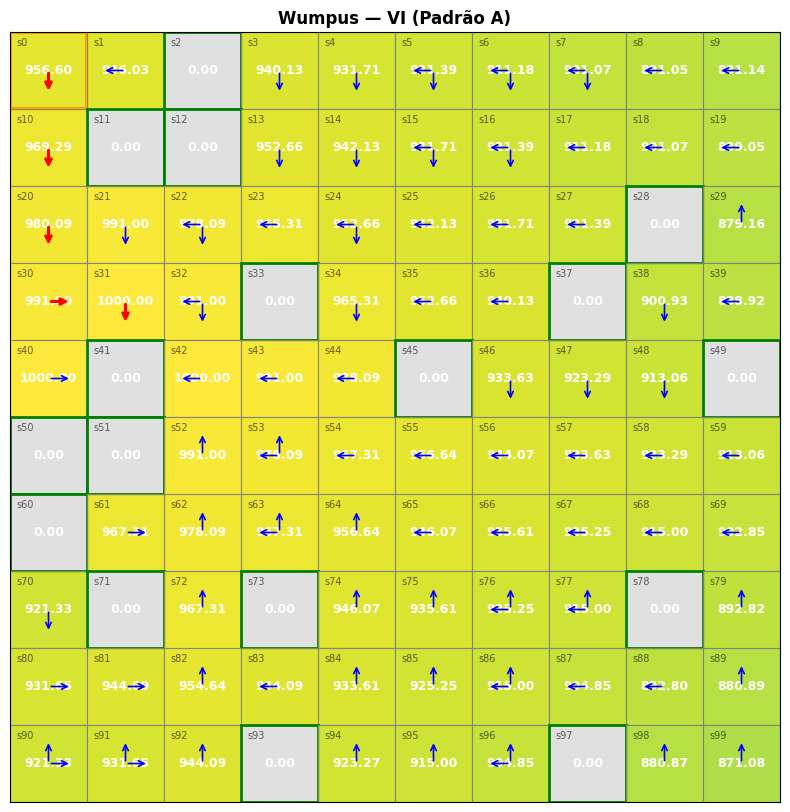

In [ ]:
vis = VisualizadorResultado(env)
vis.desenhar(V, pi, titulo="Wumpus — VI (Padrão A)")
plt.show()

In [ ]:
w_reverso = WumpusMDP(nlin=10, ncol=10, seed=42, modo="reverso")
print(w_reverso)

WumpusMDP(10x10, seed=42, gamma=0.99, modo='reverso')
  s0 = 41  ->  (x=1, y=5)  [agente]
  objetivo = 0  ->  (x=0, y=9)
  Wumpus: (8, 2)
  Ouro:   (1, 5)
  Buracos(15): [(0, 3), (9, 5), (3, 6), (3, 2), (2, 9), (1, 8), (1, 4), (8, 7), (7, 0), (1, 2), (7, 6), (5, 5), (0, 4), (2, 8), (3, 0)]


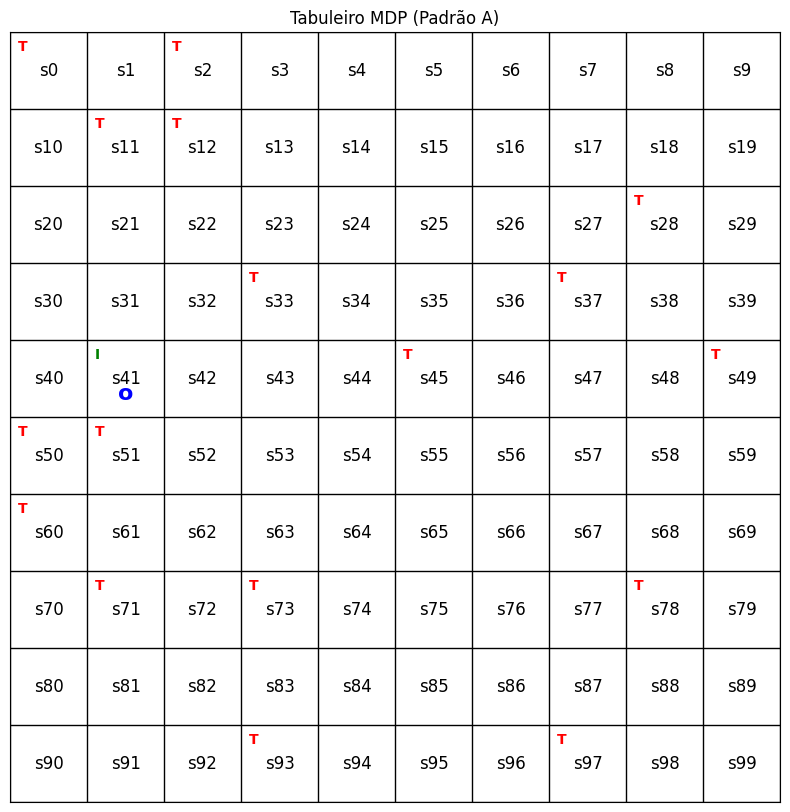

In [ ]:
env = w_reverso.criar_tabuleiro()

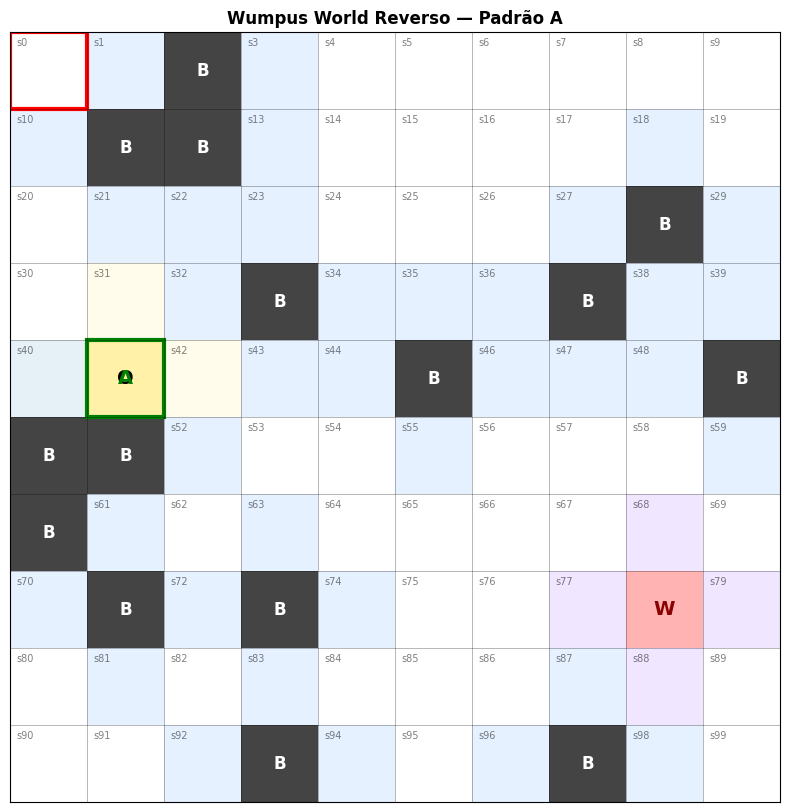

In [ ]:
w_reverso.render(titulo="Wumpus World Reverso — Padrão A")
plt.show()

In [ ]:
aval = AvaliadorVetorizado(env, xp=np, gamma=w_classico.gamma)
vi = IteracaoValor(env, aval)
V, pi = vi.treinar()

[IteracaoValor | AvaliadorVetorizado] convergiu em 19 iterações.


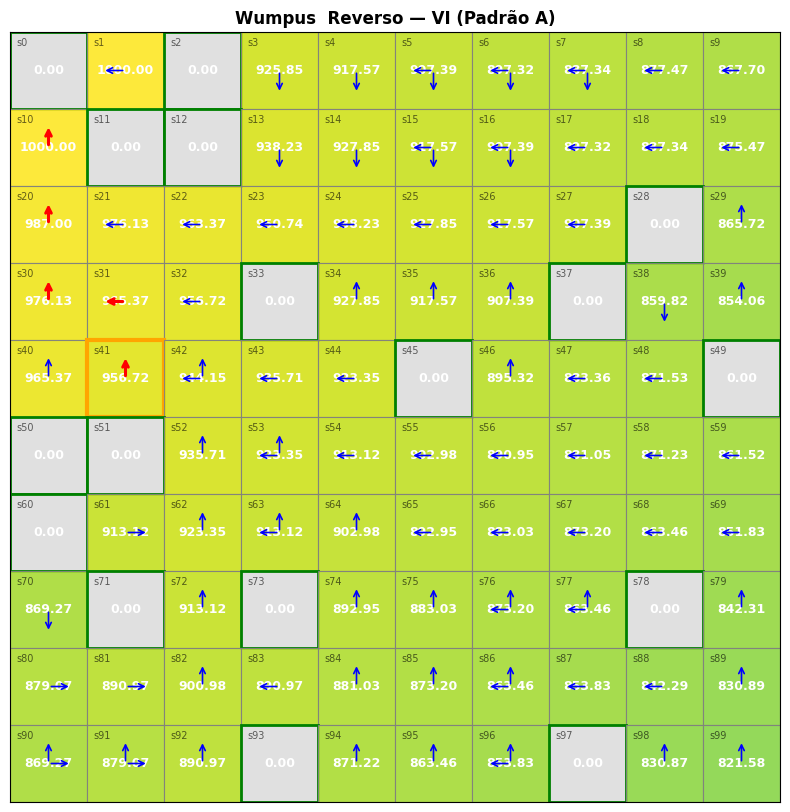

In [ ]:
vis = VisualizadorResultado(env)
vis.desenhar(V, pi, titulo="Wumpus  Reverso — VI (Padrão A)")
plt.show()